In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/wuyingwen06/avazu-ctr-train/train.csv
/kaggle/input/datasets/atirpetkar/avazu-ctr/train


In [2]:
import json, gzip, datetime as dt
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss
from sklearn.calibration import calibration_curve

DATA = "/kaggle/input/datasets/wuyingwen06/avazu-ctr-train/train.csv"
OUT  = "/kaggle/working"

# Intersection-only features: every one of these has a real counterpart your
# auction engine can supply at serving time. We deliberately DROP Avazu's
# anonymized C-features (C1, C14–C21) — they'd lift AUC but can't be mapped
# to your schema, so a model that needs them can't feed the bid path.
USECOLS = ["click", "hour", "banner_pos", "site_category", "device_type"]
DTYPE   = {"click": "int8", "hour": "int32", "banner_pos": "int16",
           "site_category": "str", "device_type": "int16"}

TOP_CATEGORIES = 20     # keep the N most frequent site_category hashes, rest -> "other"
TRAIN_ROWS     = 2_000_000   # sample the train period to this size for speed

In [3]:
# ~40M rows, but usecols keeps this cheap. Takes a few minutes to decompress.
df = pd.read_csv(DATA, usecols=USECOLS, dtype=DTYPE)
print(f"{len(df):,} rows  |  overall CTR = {df.click.mean():.4f}")

40,428,967 rows  |  overall CTR = 0.1698


In [4]:

# hour is YYMMDDHH, e.g. 14102100 -> Oct 21 2014, 00:00
df["hour_of_day"] = (df["hour"] % 100).astype("int16")
df["day"]         = ((df["hour"] // 100) % 100).astype("int16")

# Fold rare site_category hashes into "other" so the model doesn't memorize noise
top = df["site_category"].value_counts().nlargest(TOP_CATEGORIES).index
df["site_category"] = df["site_category"].where(df["site_category"].isin(top), "other")
CATEGORY_VOCAB = sorted(df["site_category"].unique().tolist())

CAT_COLS = ["device_type", "site_category", "banner_pos", "hour_of_day"]
df[CAT_COLS] = df[CAT_COLS].astype(str)   # treat all four as categorical

# TEMPORAL split — train on earlier days, test on the last 2. A random split
# would leak future traffic into training and inflate every metric; a time
# split is the honest one and mirrors what a deployed model actually faces.
days = sorted(df["day"].unique())
test_days = days[-2:]
train_df = df[~df["day"].isin(test_days)]
test_df  = df[ df["day"].isin(test_days)]

train_df = train_df.sample(min(TRAIN_ROWS, len(train_df)), random_state=42)
print(f"train {len(train_df):,}  test {len(test_df):,}  test days {test_days}")

train 2,000,000  test 8,051,546  test days [np.int16(29), np.int16(30)]


In [5]:
ohe = OneHotEncoder(handle_unknown="ignore", dtype=np.float32)
Xtr = ohe.fit_transform(train_df[CAT_COLS])
Xte = ohe.transform(test_df[CAT_COLS])
ytr, yte = train_df["click"].values, test_df["click"].values

lr = LogisticRegression(max_iter=1000, C=1.0)
lr.fit(Xtr, ytr)
p_lr = lr.predict_proba(Xte)[:, 1]

# Baseline for the modeling story — does a nonlinear model beat linear here?
oe = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
gbt = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1)
gbt.fit(oe.fit_transform(train_df[CAT_COLS]), ytr)
p_gbt = gbt.predict_proba(oe.transform(test_df[CAT_COLS]))[:, 1]

 model      auc  logloss    brier
logreg 0.591153 0.437447 0.134506
   gbt 0.605435 0.433603 0.133325


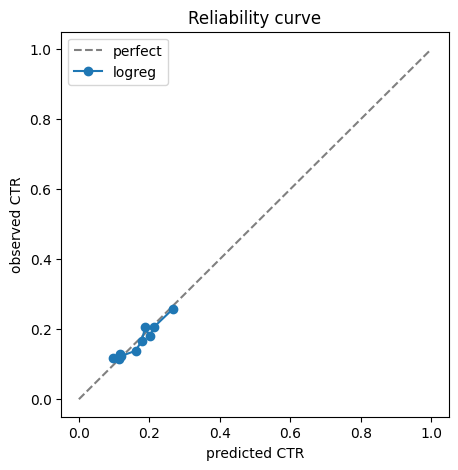

In [6]:
def report(name, y, p):
    return dict(model=name,
                auc=roc_auc_score(y, p),
                logloss=log_loss(y, p),
                brier=brier_score_loss(y, p))   # Brier: are the probabilities themselves right?

m_lr, m_gbt = report("logreg", yte, p_lr), report("gbt", yte, p_gbt)
print(pd.DataFrame([m_lr, m_gbt]).to_string(index=False))

# Reliability curve — AUC only measures ranking. Because you multiply pCTR by a
# dollar value, a model that ranks perfectly but is systematically 2x high will
# overbid every auction and burn budget. This plot is what proves it doesn't.
frac, mean = calibration_curve(yte, p_lr, n_bins=10, strategy="quantile")
plt.figure(figsize=(5,5))
plt.plot([0,1],[0,1],"--",c="gray",label="perfect")
plt.plot(mean, frac, "o-", label="logreg")
plt.xlabel("predicted CTR"); plt.ylabel("observed CTR")
plt.title("Reliability curve"); plt.legend(); plt.savefig(f"{OUT}/calibration.png", dpi=120)
plt.show()

In [8]:

# ── Artifact 1: the model, as plain coefficients ──────────────────────────────
# Exported as JSON, NOT a pickle, so your FastAPI process scores with a numpy
# dot-product and NEVER imports scikit-learn (keeps you under Render's 512MB).
# Key order below matches OneHotEncoder's output order exactly, so weights align.
weights = {}
for col, cats in zip(CAT_COLS, ohe.categories_):
    for c in cats:
        weights[f"{col}={c}"] = None   # placeholder to preserve order
for (name), w in zip(list(weights.keys()), lr.coef_[0]):
    weights[name] = float(w)

model_artifact = {
    "model": "logistic_regression",
    "trained_at": dt.datetime.utcnow().isoformat() + "Z",
    "features": CAT_COLS,
    "intercept": float(lr.intercept_[0]),
    "weights": weights,
    "baseline_ctr": float(test_df["click"].mean()),
    "category_vocab": CATEGORY_VOCAB,     # values NOT in here map to "other" at serving
    # Documented convention mapping YOUR engine's device classes to Avazu's
    # numeric codes. Avazu's device_type semantics are undocumented, so this is
    # a fixed, arbitrary-but-stated choice — say so in the README.
    "device_map": {"desktop": "0", "mobile": "1", "tablet": "4"},
    "metrics": {"logreg": m_lr, "gbt": m_gbt},
}
with open(f"{OUT}/ctr_model.json", "w") as f:
    json.dump(model_artifact, f, indent=2)

# ── Artifact 2: empirical CTR lookup, computed on the HELD-OUT test split ──────
# This is the ground truth your seed simulator uses to decide click/no-click.
# The model estimates CTR from the train split; this table is the real answer
# from data the model never saw — so measured A/B lift is genuine, not circular.
MIN_COUNT = 100
g = test_df.groupby(CAT_COLS)["click"].agg(["mean", "count"])
empirical = {"__baseline__": float(test_df["click"].mean())}
for keys, row in g[g["count"] >= MIN_COUNT].iterrows():
    empirical["|".join(f"{c}={v}" for c, v in zip(CAT_COLS, keys))] = float(row["mean"])
with open(f"{OUT}/empirical_ctr.json", "w") as f:
    json.dump(empirical, f, indent=2)

print(f"wrote ctr_model.json ({len(weights)} weights) and "
      f"empirical_ctr.json ({len(empirical)} combos)")

/tmp/ipykernel_58/1532518413.py:14: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "trained_at": dt.datetime.utcnow().isoformat() + "Z",


wrote ctr_model.json (57 weights) and empirical_ctr.json (573 combos)


In [10]:

# Empirical-Bayes smoothing: pull sparse/degenerate segments toward baseline.
# Well-sampled segments (large n) are essentially unchanged; the 0.0 and 1.0
# outliers collapse toward 0.163. ALPHA is a pseudo-count of "prior" impressions.
ALPHA = 250
base  = float(test_df["click"].mean())
g = test_df.groupby(CAT_COLS)["click"].agg(clicks="sum", n="count")

empirical = {"__baseline__": base}
for keys, row in g.iterrows():
    if row["n"] >= 50:
        ctr = (row["clicks"] + ALPHA * base) / (row["n"] + ALPHA)
        empirical["|".join(f"{c}={v}" for c, v in zip(CAT_COLS, keys))] = float(ctr)

with open(f"{OUT}/empirical_ctr.json", "w") as f:
    json.dump(empirical, f, indent=2)

vals = np.array([v for k, v in empirical.items() if k != "__baseline__"])
print(f"{len(vals)} segments  |  range {vals.min():.4f}–{vals.max():.4f}  "
      f"|  p10/p90 {np.quantile(vals,0.1):.4f}/{np.quantile(vals,0.9):.4f}")

646 segments  |  range 0.0238–0.6356  |  p10/p90 0.0658/0.2453


In [9]:
vals = np.array([v for k, v in empirical.items() if k != "__baseline__"])
base = empirical["__baseline__"]
print(f"baseline CTR      {base:.4f}")
print(f"segments          {len(vals)}")
print(f"CTR range         {vals.min():.4f} – {vals.max():.4f}")
print(f"p10 / p50 / p90   {np.quantile(vals,0.1):.4f} / "
      f"{np.quantile(vals,0.5):.4f} / {np.quantile(vals,0.9):.4f}")
print(f"spread (p90/p10)  {np.quantile(vals,0.9)/max(np.quantile(vals,0.1),1e-9):.1f}x")
# EV bidding's value comes directly from this spread, NOT from AUC.

baseline CTR      0.1632
segments          572
CTR range         0.0000 – 1.0000
p10 / p50 / p90   0.0177 / 0.1051 / 0.2965
spread (p90/p10)  16.8x


## Hierarchical CTR table (v2)

The table above leaves most of the engine's serving contexts without a row, so
the click simulator gave them all the global baseline and the A/B had nothing to
measure. This rebuilds it with every level of the hierarchy, each shrunk toward
its parent, and then checks the result on the contexts the engine actually
serves. Download `empirical_ctr.json` from the output when it finishes and
replace `backend/app/ml/artifacts/empirical_ctr.json`.

In [ ]:
# ── Artifact 2, v2: a hierarchical empirical-Bayes CTR table ──────────────────
# The table above only has rows at full detail (device × category × position ×
# hour), and a cell under the count threshold is simply missing. Avazu is ~92%
# one device type, so most of the contexts the engine actually serves have no
# row, and the simulator gave them all the same global baseline. With the truth
# flat across most impressions, EV bidding has nothing to exploit: no model can
# find cheaper clicks where every click is equally likely. The demo's A/B could
# not show a difference whatever the model did.
#
# Instead, estimate every level of a hierarchy, each shrunk toward its PARENT
# rather than toward the global mean:
#     category → device × category → … × position → … × hour
# A sparse cell then keeps everything the data does say about its device and
# category, and a well-sampled one is essentially its raw rate. The serving
# lookup backs off level by level in the same order (app/ml/simulation.py).
LEVELS = [   # most specific first, matching BACKOFF_LEVELS in the engine
    ["device_type", "site_category", "banner_pos", "hour_of_day"],
    ["device_type", "site_category", "banner_pos"],
    ["device_type", "site_category"],
    ["site_category"],
]
ALPHA     = 250   # prior strength, in impressions: n=250 is a 50/50 blend with the parent
MIN_COUNT = 50    # cells below this are not written; serving uses the parent instead

def level_key(values, cols):
    return "|".join(f"{c}={values[c]}" for c in cols)

def lookup(table, values):
    """Same backoff as the engine: the most specific level present wins."""
    for cols in LEVELS:
        if all(c in values for c in cols) and level_key(values, cols) in table:
            return table[level_key(values, cols)]
    return table["__baseline__"]

base = float(test_df["click"].mean())
empirical = {"__baseline__": base}
# Coarsest first, so every parent is in the table before its children need it.
for cols in reversed(LEVELS):
    g = test_df.groupby(cols, observed=True)["click"].agg(clicks="sum", n="count")
    for vals, row in g[g["n"] >= MIN_COUNT].iterrows():
        values = dict(zip(cols, vals if isinstance(vals, tuple) else (vals,)))
        prior = lookup(empirical, values)   # the parent: this level is not written yet
        empirical[level_key(values, cols)] = float(
            (row["clicks"] + ALPHA * prior) / (row["n"] + ALPHA))

with open(f"{OUT}/empirical_ctr.json", "w") as f:
    json.dump(empirical, f, indent=2)

counts = {len(cols): sum(1 for k in empirical if k.count("|") == len(cols) - 1
                         and not k.startswith("__")) for cols in LEVELS}
print(f"wrote empirical_ctr.json: {len(empirical) - 1} segments "
      + ", ".join(f"{counts[len(c)]} at {' × '.join(c)}" for c in LEVELS))

In [ ]:
# ── Does the A/B have anything to measure? Check on the SERVING distribution ──
# Test-set AUC says how the model ranks Avazu traffic. EV bidding's gain on the
# demo depends on something else: across the contexts the engine actually
# serves, does the true CTR vary, and does the model's pCTR follow it? These
# mirror app/ml/mappings.py: the engine's devices, its publisher categories
# (the first six of the sorted vocabulary) and the slot positions it uses.
from scipy.stats import pearsonr, spearmanr

ENGINE_DEVICES    = ["0", "1", "4"]                                  # desktop, mobile, tablet
ENGINE_CATEGORIES = sorted(c for c in CATEGORY_VOCAB if c != "other")[:6]
ENGINE_POSITIONS  = ["0", "1", "2"]

contexts = pd.DataFrame(
    [(d, c, p, str(h)) for d in ENGINE_DEVICES for c in ENGINE_CATEGORIES
     for p in ENGINE_POSITIONS for h in range(24)],
    columns=CAT_COLS)
rows = contexts.to_dict("records")
truth = np.array([lookup(empirical, r) for r in rows])
level = pd.Series([next((" × ".join(cols) for cols in LEVELS
                         if level_key(r, cols) in empirical), "baseline") for r in rows])
pctr = lr.predict_proba(ohe.transform(contexts[CAT_COLS]))[:, 1]

print(f"{len(rows)} serving contexts, resolved at:")
print(level.value_counts().to_string())
print(f"\ntrue CTR  p10/p50/p90  {np.quantile(truth, 0.1):.3f} / "
      f"{np.quantile(truth, 0.5):.3f} / {np.quantile(truth, 0.9):.3f}")
print(f"pCTR vs truth          pearson {pearsonr(pctr, truth)[0]:.2f}   "
      f"spearman {spearmanr(pctr, truth)[0]:.2f}")
print(f"mean pCTR / mean truth {pctr.mean():.3f} / {truth.mean():.3f}")